# SomnIA: metaheurísticas y reglas evolutivas para mejorar VGG19 + Attention (Colab Pro, GPU)

**Objetivo.** Mejorar la red VGG19 + Attention (estima el cierre de cada ojo y luego clasifica la somnolencia por fotograma) buscando sus hiperparámetros con **cuatro metaheurísticas bioinspiradas**: algoritmo genético, colonia de abejas, luciérnagas y murciélagos. Después se reemplaza el clasificador final por **reglas evolutivas** (Michigan y Pittsburgh). Todo se plantea como un experimento controlado, según el diseño de experimentos de la clase.

**Cómputo.** Cada evaluación de la aptitud **entrena la red completa** (VGG19 desde ImageNet + atención + MLP) en la GPU de Colab Pro, con precisión mixta, `channels_last` y los recortes cargados en la memoria de la GPU. Cada evaluación se guarda en Drive (`SomnIA_colab/cache`): si Colab se desconecta, al volver a ejecutar se retoma donde iba.

## Diseño de los experimentos

| | **Experimento 1: metaheurísticas** | **Experimento 2: reglas evolutivas** |
|---|---|---|
| Unidad experimental | Red VGG19 + Attention completa | Clasificador final de somnolencia |
| **Variables independientes (factores)** | Método de búsqueda: Paper (sin búsqueda), Aleatoria, Genético, Abejas (ABC), Luciérnagas, Murciélagos (6 niveles) | Clasificador: regresión logística, Michigan, Pittsburgh (3) × red de entrada: original o optimizada (2) |
| **Variables dependientes (respuestas)** | Accuracy y F1 de somnolencia en **prueba** (personas nunca vistas), aptitud en validación y tiempo de cómputo | Accuracy y F1 en prueba, número de reglas |
| **Variables intervinientes (fijas)** | Partición por persona (pliegue 0), datos (1 de cada 6 fotogramas en entrenamiento), máximo 4 épocas con paciencia 2, aumento de datos, calibración por persona, presupuesto y población iguales para todos | Mismas características $[z_L, z_R, \text{cierre}_L, \text{cierre}_R]$ y misma partición |
| Variables no controladas | Calidad de las etiquetas de MediaPipe y GPU asignada por Colab | Ídem |
| Casos × repeticiones | 6 casos × 3 repeticiones (semillas) | 6 casos × 3 repeticiones |
| Análisis | ANOVA de un factor + Tukey HSD | ANOVA de dos factores con interacción |

**Espacio de búsqueda** (8 genes codificados en [0, 1]):

| Gen | Rango | Paper |
|---|---|---|
| Tasa de aprendizaje | 1e-5 a 3e-3 (escala logarítmica) | 1e-4 |
| Neuronas de la capa 1 del MLP | 32 a 1024 | 512 |
| Neuronas de la capa 2 | 25 % a 100 % de la capa 1 | 256 |
| Dropout | 0 a 0,7 | 0,5 |
| Neuronas del cuello de la atención | 4 a 128 | 32 |
| Weight decay | 1e-6 a 1e-2 | 0 |
| Convoluciones congeladas de la VGG19 | 0 a 16 | 10 |
| Tamaño de lote | 32, 64, 128 | 64 |

**Aptitud** = accuracy de somnolencia en **validación** (personas que no están en entrenamiento ni en prueba). La **prueba** (otras 5 personas) no participa en la búsqueda: solo se reporta para la mejor configuración que encuentra cada algoritmo.

## 0. Entorno: GPU de Colab Pro y datos en Drive

In [ ]:
import os, sys, time, json, shutil
from pathlib import Path
from google.colab import drive
drive.mount("/content/drive")
CARPETA = Path("/content/drive/MyDrive/SomnIA_colab")          # datos subidos desde el proyecto + caché de resultados
TRABAJO = Path("/content/somnia"); TRABAJO.mkdir(exist_ok=True); os.chdir(TRABAJO)
for f in ["ojos_pliegue0.npz", "meta_ojos.csv"]:                # copia local: se lee más rápido que desde Drive
    if not (TRABAJO / f).exists(): shutil.copy(CARPETA / f, TRABAJO / f)
!nvidia-smi --query-gpu=name,memory.total --format=csv

Mounted at /content/drive
name, memory.total [MiB]
NVIDIA RTX PRO 6000 Blackwell Server Edition, 97887 MiB


## 1. Código: metaheurísticas, reglas evolutivas y entrenamiento de la red
Se escriben dos módulos: `somnia_meta.py` (calibración, metaheurísticas, Michigan y Pittsburgh) y `somnia_red.py` (VGG19 + Attention completa en la GPU).

In [ ]:
%%writefile somnia_meta.py
"""SomnIA — metaheurísticas y sistemas de reglas evolutivos sobre la red VGG19 + Attention.

La VGG19 (afinada en el pliegue 0) queda fija y se usa como extractor: cada ojo es un vector de 512
números (promedio global de sus mapas). Lo que se optimiza es la parte que decide: atención por canal
+ MLP. Esto es exactamente la red original, porque  mean(f * s) = s * mean(f)  cuando la nota s es por canal.

Partes:
  1. Espacio de búsqueda  (8 hiperparámetros codificados en [0, 1]^8).
  2. Función de aptitud    (entrena atención + MLP y mide la accuracy de somnolencia en VALIDACIÓN).
  3. Metaheurísticas      : aleatoria (referencia), genético, colonia de abejas (ABC), luciérnagas y murciélagos.
  4. Reglas evolutivas    : Michigan (cada individuo = una regla) y Pittsburgh (cada individuo = un conjunto de reglas).
"""
import math
import time

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, recall_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

DEV = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
COLS = ["z_L", "z_R", "closure_L", "closure_R"]


# =============================================================== 1. datos
class Datos:
    """Vectores de 512 características por ojo + partición por persona del pliegue 0 (train / val / test)."""

    def __init__(self, X, meta, n_calib=20, paso_train=3):
        self.meta = meta.reset_index(drop=True)
        self.X = torch.tensor(np.asarray(X, np.float32), device=DEV)                       # (N, 2, 512)
        self.y = torch.tensor(self.meta[["blink_L", "blink_R"]].to_numpy(np.float32), device=DEV)
        orden = self.meta.sort_values(["prefix", "frame"]).index
        sp = self.meta["split"]
        tr = orden[sp[orden].eq("train").to_numpy()]
        self.idx = {"train": tr[::paso_train].to_numpy(),          # 1 de cada 3 fotogramas (igual que el modelo original)
                    "val": orden[sp[orden].eq("val").to_numpy()].to_numpy(),
                    "test": orden[sp[orden].eq("test").to_numpy()].to_numpy()}
        # Referencia de calibración: primeras n fotos alerta de cada identidad (no depende del modelo -> se precalcula)
        m = self.meta
        self.grupo = m["identity"].astype("category").cat.codes.to_numpy()
        self.es_ref = np.zeros(len(m), bool)
        for _, g in m.groupby("identity"):
            ref = g[g["label"] == 0].sort_values(["prefix", "frame"]).index[:n_calib]
            if len(ref) == 0:
                p = m[(m["person"] == g["person"].iloc[0]) & (m["label"] == 0)]
                ref = p.sort_values(["prefix", "frame"]).index[:n_calib]
            self.es_ref[ref] = True
        self.ref_de = {}
        for gid in np.unique(self.grupo):
            g = np.where(self.grupo == gid)[0]
            r = g[self.es_ref[g]]
            if len(r) == 0:
                r = np.where(self.es_ref & (m["person"].to_numpy() == m.loc[g[0], "person"]))[0]
            self.ref_de[gid] = r
        self.label = m["label"].to_numpy()


def calibrar(datos, idx, cierre):
    """cierre: (len(idx), 2). Devuelve la matriz [z_L, z_R, cierre_L, cierre_R] y la máscara de fotos evaluables."""
    full = np.full((len(datos.meta), 2), np.nan, np.float32)
    full[idx] = cierre
    z = np.full((len(idx), 2), np.nan, np.float32)
    g_idx = datos.grupo[idx]
    for gid in np.unique(g_idx):
        r = datos.ref_de[gid]
        sel = g_idx == gid
        if len(r) == 0 or np.isnan(full[r]).any():
            continue
        z[sel] = (cierre[sel] - full[r].mean(0)) / (full[r].std(0, ddof=1) + 1e-3)
    F_ = np.concatenate([z, cierre], 1)
    ok = ~np.isnan(F_).any(1) & ~datos.es_ref[idx]
    return F_, ok


# =============================================================== 2. red (atención + MLP) y aptitud
NOMBRES = ["tasa_aprendizaje", "neuronas_1", "proporcion_capa_2", "dropout", "cuello_atencion", "weight_decay", "epocas", "lote"]


def decodificar(u):
    u = np.clip(np.asarray(u, float), 0, 1)
    n1 = int(round(2 ** (5 + 5 * u[1])))                        # 32 .. 1024
    return {"tasa_aprendizaje": float(10 ** (-5 + 3 * u[0])),    # 1e-5 .. 1e-2
            "neuronas_1": n1,
            "neuronas_2": max(8, int(round(n1 * (0.25 + 0.75 * u[2])))),
            "dropout": round(float(0.7 * u[3]), 3),             # 0 .. 0.7
            "cuello_atencion": int(round(2 ** (2 + 5 * u[4]))),  # 4 .. 128 neuronas en el cuello de la atención
            "weight_decay": float(10 ** (-6 + 4 * u[5])),       # 1e-6 .. 1e-2
            "epocas": int(round(3 + 17 * u[6])),                 # 3 .. 20
            "lote": int(2 ** round(7 + 3 * u[7]))}               # 128 .. 1024


# Configuración del paper / del modelo original (referencia)
CONFIG_PAPER = {"tasa_aprendizaje": 1e-4, "neuronas_1": 512, "neuronas_2": 256, "dropout": 0.5, "cuello_atencion": 32,
                "weight_decay": 0.0, "epocas": 6, "lote": 64}


class Cabeza(nn.Module):
    """Atención por canal (Squeeze-and-Excitation) + MLP, igual que en VGG19 + Attention."""

    def __init__(self, c):
        super().__init__()
        self.att = nn.Sequential(nn.Linear(512, c["cuello_atencion"]), nn.ReLU(), nn.Linear(c["cuello_atencion"], 512), nn.Sigmoid())
        self.mlp = nn.Sequential(nn.Linear(512, c["neuronas_1"]), nn.ReLU(), nn.Dropout(c["dropout"]),
                                 nn.Linear(c["neuronas_1"], c["neuronas_2"]), nn.ReLU(), nn.Dropout(c["dropout"]),
                                 nn.Linear(c["neuronas_2"], 1))

    def forward(self, g):
        return self.mlp(g * self.att(g)).squeeze(-1)


def entrenar_cabeza(datos, c, semilla=0):
    torch.manual_seed(semilla)
    net = Cabeza(c).to(DEV)
    opt = torch.optim.AdamW(net.parameters(), lr=c["tasa_aprendizaje"], weight_decay=c["weight_decay"])
    tr = torch.as_tensor(datos.idx["train"], device=DEV)
    X = datos.X[tr].reshape(-1, 512); y = datos.y[tr].reshape(-1)
    g = torch.Generator(device=DEV).manual_seed(semilla)
    net.train()
    for _ in range(c["epocas"]):
        perm = torch.randperm(len(X), device=DEV, generator=g)
        for i in range(0, len(perm), c["lote"]):
            j = perm[i:i + c["lote"]]
            loss = F.binary_cross_entropy_with_logits(net(X[j]), y[j])
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
    return net.eval()


@torch.no_grad()
def cierre(net, datos, idx):
    x = datos.X[torch.as_tensor(idx, device=DEV)]
    return torch.sigmoid(net(x.reshape(-1, 512))).reshape(-1, 2).cpu().numpy()


def evaluar(c, datos, semilla=0, particiones=("val",), devolver=False):
    """Entrena atención + MLP con la configuración c y mide la clasificación de somnolencia calibrada por persona."""
    net = entrenar_cabeza(datos, c, semilla)
    ctr = cierre(net, datos, datos.idx["train"])
    Ftr, ok = calibrar(datos, datos.idx["train"], ctr)
    ytr = datos.label[datos.idx["train"]]
    if np.isnan(ctr).any() or ok.sum() < 50 or len(np.unique(ytr[ok])) < 2:
        return ({p: {"accuracy": 0.0, "f1": 0.0} for p in particiones}, None) if devolver else 0.0
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")).fit(Ftr[ok], ytr[ok])
    res, salida = {}, {"train": (Ftr[ok], ytr[ok])}
    for p in particiones:
        Fp, okp = calibrar(datos, datos.idx[p], cierre(net, datos, datos.idx[p]))
        yp, pred = datos.label[datos.idx[p]][okp], clf.predict(Fp[okp])
        corr = float(np.corrcoef(Fp[okp][:, 2:].ravel(), datos.meta.loc[datos.idx[p][okp], ["blink_L", "blink_R"]].to_numpy().ravel())[0, 1])
        res[p] = {"accuracy": accuracy_score(yp, pred), "f1": f1_score(yp, pred), "recall_drowsy": recall_score(yp, pred),
                  "recall_alerta": recall_score(yp, pred, pos_label=0), "r_cierre": corr}
        salida[p] = (Fp[okp], yp)
    if devolver:
        return res, salida
    return res[particiones[0]]["accuracy"]


class Aptitud:
    """Envuelve evaluar(): guarda cada evaluación (para curvas de convergencia) y respeta el presupuesto."""

    def __init__(self, datos, presupuesto, semilla):
        self.datos, self.presupuesto, self.semilla = datos, presupuesto, semilla
        self.historial, self.t0 = [], time.time()

    def __call__(self, u):
        if len(self.historial) >= self.presupuesto:
            return -1.0
        f = evaluar(decodificar(u), self.datos, semilla=self.semilla)
        mejor = max([h["aptitud"] for h in self.historial] + [f])
        self.historial.append({"evaluacion": len(self.historial) + 1, "aptitud": f, "mejor": mejor, "u": np.array(u),
                               "segundos": time.time() - self.t0})
        return f

    @property
    def agotado(self):
        return len(self.historial) >= self.presupuesto

    def mejor_u(self):
        return max(self.historial, key=lambda h: h["aptitud"])["u"]


# =============================================================== 3. metaheurísticas (maximizan la aptitud)
D_GENES = len(NOMBRES)


def busqueda_aleatoria(fit, rng, pob=8):
    while not fit.agotado:
        fit(rng.random(D_GENES))


def genetico(fit, rng, pob=8, p_cruce=0.9, p_mut=0.2, sigma=0.15, alpha=0.5):
    """Algoritmo genético real: torneo binario, cruce BLX-alpha, mutación gaussiana y elitismo (1 individuo)."""
    P = rng.random((pob, D_GENES)); f = np.array([fit(x) for x in P])
    while not fit.agotado:
        hijos = [P[f.argmax()].copy()]                                    # elitismo
        while len(hijos) < pob:
            a, b = (P[max(rng.choice(pob, 2, replace=False), key=lambda i: f[i])] for _ in range(2))
            if rng.random() < p_cruce:
                lo, hi = np.minimum(a, b), np.maximum(a, b); d = hi - lo
                h = rng.uniform(lo - alpha * d, hi + alpha * d)
            else:
                h = a.copy()
            m = rng.random(D_GENES) < p_mut
            h[m] += rng.normal(0, sigma, m.sum())
            hijos.append(np.clip(h, 0, 1))
        P = np.array(hijos)
        f = np.array([f.max()] + [fit(x) for x in P[1:]])
    return P[f.argmax()]


def abejas(fit, rng, pob=8, limite=3):
    """Colonia artificial de abejas (ABC, Karaboga 2005): obreras, observadoras y exploradoras."""
    n = max(2, pob // 2)                                 # fuentes de alimento = obreras
    S = rng.random((n, D_GENES)); f = np.array([fit(x) for x in S]); intentos = np.zeros(n, int)

    def vecina(i):
        k = rng.choice([j for j in range(n) if j != i]); d = rng.integers(D_GENES)
        v = S[i].copy(); v[d] = np.clip(S[i, d] + rng.uniform(-1, 1) * (S[i, d] - S[k, d]), 0, 1)
        fv = fit(v)
        if fv > f[i]:
            S[i], f[i], intentos[i] = v, fv, 0
        else:
            intentos[i] += 1

    while not fit.agotado:
        for i in range(n):                               # fase de obreras
            vecina(i)
        p = (f - f.min() + 1e-9); p = p / p.sum()
        for _ in range(n):                               # fase de observadoras (eligen fuentes según su calidad)
            vecina(rng.choice(n, p=p))
        i = intentos.argmax()                            # fase de exploradoras (abandonan una fuente agotada)
        if intentos[i] > limite:
            S[i] = rng.random(D_GENES); f[i] = fit(S[i]); intentos[i] = 0
    return S[f.argmax()]


def luciernagas(fit, rng, pob=8, beta0=1.0, gamma=1.0, alpha=0.2, decaimiento=0.9):
    """Algoritmo de luciérnagas (Yang 2008): cada luciérnaga vuela hacia las más brillantes (mejor aptitud)."""
    L = rng.random((pob, D_GENES)); f = np.array([fit(x) for x in L])
    while not fit.agotado:
        for i in range(pob):
            for j in range(pob):
                if f[j] > f[i] and not fit.agotado:
                    r2 = np.sum((L[i] - L[j]) ** 2)
                    L[i] = np.clip(L[i] + beta0 * math.exp(-gamma * r2) * (L[j] - L[i]) + alpha * (rng.random(D_GENES) - 0.5), 0, 1)
                    f[i] = fit(L[i])
            if f[i] >= f.max() and not fit.agotado:      # la más brillante hace un vuelo aleatorio
                v = np.clip(L[i] + alpha * (rng.random(D_GENES) - 0.5), 0, 1); fv = fit(v)
                if fv > f[i]:
                    L[i], f[i] = v, fv
        alpha *= decaimiento
    return L[f.argmax()]


def murcielagos(fit, rng, pob=8, fmin=0.0, fmax=1.0, A0=0.9, r0=0.5, alfa=0.9, gam=0.9):
    """Algoritmo de murciélagos (Yang 2010): ecolocalización con frecuencia, volumen (A) y tasa de pulsos (r)."""
    B = rng.random((pob, D_GENES)); V = np.zeros_like(B); f = np.array([fit(x) for x in B])
    A, r, t = np.full(pob, A0), np.zeros(pob), 0
    while not fit.agotado:
        t += 1; best = B[f.argmax()].copy()
        for i in range(pob):
            if fit.agotado:
                break
            freq = fmin + (fmax - fmin) * rng.random()
            V[i] = V[i] + (B[i] - best) * freq
            x = np.clip(B[i] + V[i], 0, 1)
            if rng.random() > r[i]:                      # búsqueda local alrededor del mejor
                x = np.clip(best + 0.1 * A.mean() * rng.normal(size=D_GENES), 0, 1)
            fx = fit(x)
            if fx >= f[i] and rng.random() < A[i]:       # acepta y "baja el volumen / sube los pulsos"
                B[i], f[i] = x, fx
                A[i] *= alfa; r[i] = r0 * (1 - math.exp(-gam * t))
    return B[f.argmax()]


ALGORITMOS = {"Aleatoria": busqueda_aleatoria, "Genético": genetico, "Abejas (ABC)": abejas,
              "Luciérnagas": luciernagas, "Murciélagos": murcielagos}


# =============================================================== 4. sistemas de reglas evolutivos
def _coincide(lo, hi, X):
    """lo, hi: (R, d) límites de cada regla (nan = 'no importa'); X: (n, d). Devuelve (R, n) booleano."""
    lo_ = np.where(np.isnan(lo), -np.inf, lo); hi_ = np.where(np.isnan(hi), np.inf, hi)
    return ((X[None] >= lo_[:, None]) & (X[None] <= hi_[:, None])).all(-1)


def texto_regla(lo, hi, clase, nombres=COLS):
    cond = [f"{n} ∈ [{a:.2f}, {b:.2f}]" for n, a, b in zip(nombres, lo, hi) if not np.isnan(a)]
    return ("SI " + " Y ".join(cond) if cond else "SIEMPRE") + f" → {'Drowsy' if clase else 'Alerta'}"


class Michigan:
    """Sistema clasificador tipo Michigan (estilo UCS, Bernadó-Mansilla 2003).
    Cada individuo es UNA regla; la población completa es el clasificador. Las reglas compiten por su
    precisión y el AG solo actúa dentro del conjunto correcto [C] de cada ejemplo."""

    def __init__(self, N=120, p_no_importa=0.4, nu=5, theta_ga=25, mu=0.1, rng=None):
        self.N, self.p_ni, self.nu, self.theta_ga, self.mu = N, p_no_importa, nu, theta_ga, mu
        self.rng = rng or np.random.default_rng(0)

    def _cubrir(self, x, c, ancho):
        lo, hi = x - ancho * self.rng.random(len(x)), x + ancho * self.rng.random(len(x))
        ni = self.rng.random(len(x)) < self.p_ni
        lo[ni] = hi[ni] = np.nan
        return lo, hi, c

    def fit(self, X, y, pasadas=3, n_muestra=4000):
        self.mu_, self.sd_ = X.mean(0), X.std(0) + 1e-9
        self.defecto_ = int(np.bincount(y).argmax())
        X = (X - self.mu_) / self.sd_; d = X.shape[1]
        if len(X) > n_muestra:
            s = self.rng.choice(len(X), n_muestra, replace=False); X, y = X[s], y[s]
        self.lo, self.hi = np.empty((0, d)), np.empty((0, d))
        self.c, self.ok, self.exp, self.ts = (np.empty(0, int), np.empty(0), np.empty(0), np.empty(0))
        t = 0
        for _ in range(pasadas):
            for k in self.rng.permutation(len(X)):
                t += 1; x, c = X[k], y[k]
                M = _coincide(self.lo, self.hi, x[None])[:, 0] if len(self.c) else np.zeros(0, bool)
                C = M & (self.c == c)
                if not C.any():                                     # cubrimiento: crea una regla para este ejemplo
                    lo, hi, cc = self._cubrir(x.copy(), c, 0.8)
                    self._agregar(lo, hi, cc)
                    M = _coincide(self.lo, self.hi, x[None])[:, 0]; C = M & (self.c == c)   # el borrado pudo cambiar índices
                self.exp[M] += 1; self.ok[C] += 1
                if C.any() and t - self.ts[C].mean() > self.theta_ga:           # AG en el conjunto correcto
                    self.ts[C] = t; self._ag(np.where(C)[0], d)
        return self

    def _agregar(self, lo, hi, c):
        self.lo = np.vstack([self.lo, lo]); self.hi = np.vstack([self.hi, hi])
        self.c = np.append(self.c, c); self.ok = np.append(self.ok, 0.0); self.exp = np.append(self.exp, 0.0)
        self.ts = np.append(self.ts, 0.0)
        if len(self.c) > self.N:                                    # borrado: sale la regla menos apta
            j = np.argmin(self.aptitud() + 1e-3 * self.exp)
            for a in ("lo", "hi"):
                setattr(self, a, np.delete(getattr(self, a), j, 0))
            for a in ("c", "ok", "exp", "ts"):
                setattr(self, a, np.delete(getattr(self, a), j))

    def aptitud(self):
        return (self.ok / np.maximum(self.exp, 1)) ** self.nu

    def _ag(self, C, d):
        fit = self.aptitud()[C] + 1e-9
        p1, p2 = self.rng.choice(C, 2, p=fit / fit.sum())
        lo, hi = self.lo[p1].copy(), self.hi[p1].copy()
        m = self.rng.random(d) < 0.5                                # cruce uniforme
        lo[m], hi[m] = self.lo[p2][m], self.hi[p2][m]
        for g in np.where(self.rng.random(d) < self.mu)[0]:        # mutación: mueve límites o activa/desactiva la condición
            if np.isnan(lo[g]):
                lo[g], hi[g] = -1 - self.rng.random(), 1 + self.rng.random()
            elif self.rng.random() < 0.3:
                lo[g] = hi[g] = np.nan
            else:
                lo[g] += self.rng.normal(0, 0.3); hi[g] += self.rng.normal(0, 0.3)
        if not np.isnan(lo).all():
            lo, hi = np.fmin(lo, hi), np.fmax(lo, hi)
        self._agregar(lo, hi, self.c[p1])

    def predict(self, X):
        X = (X - self.mu_) / self.sd_
        M = _coincide(self.lo, self.hi, X)
        w = (self.aptitud() * (self.exp > 5))[:, None] * M
        votos1 = (w * (self.c == 1)[:, None]).sum(0); votos0 = (w * (self.c == 0)[:, None]).sum(0)
        return np.where(votos1 + votos0 == 0, self.defecto_, (votos1 > votos0).astype(int))

    def reglas(self, k=8):
        orden = np.argsort(-(self.aptitud() * np.minimum(self.exp, 200)))[:k]
        return [(texto_regla(self.lo[i] * self.sd_ + self.mu_, self.hi[i] * self.sd_ + self.mu_, self.c[i]),
                 self.ok[i] / max(self.exp[i], 1), int(self.exp[i])) for i in orden]


class Pittsburgh:
    """Sistema clasificador tipo Pittsburgh (estilo GABIL, De Jong 1993).
    Cada individuo es un CONJUNTO COMPLETO de reglas (lista de decisión + clase por defecto);
    el AG evoluciona clasificadores enteros y la aptitud es la exactitud balanceada de todo el conjunto."""

    def __init__(self, pob=40, generaciones=60, max_reglas=6, rng=None):
        self.pob, self.gen, self.R = pob, generaciones, max_reglas
        self.rng = rng or np.random.default_rng(0)

    def _regla(self, X, y):
        k = self.rng.integers(len(X)); x = X[k]
        lo, hi = x - self.rng.random(X.shape[1]), x + self.rng.random(X.shape[1])
        ni = self.rng.random(X.shape[1]) < 0.5; lo[ni] = hi[ni] = np.nan
        return lo, hi, int(y[k])

    def _pred(self, ind, X):
        lo, hi, c, defecto = ind
        out = np.full(len(X), defecto)
        if len(c):
            M = _coincide(lo, hi, X)
            primero = np.where(M.any(0), M.argmax(0), -1)            # lista de decisión: manda la primera regla que coincide
            out[primero >= 0] = c[primero[primero >= 0]]
        return out

    def _apt(self, ind, X, y):
        return balanced_accuracy_score(y, self._pred(ind, X)) - 0.002 * len(ind[2])

    def fit(self, X, y, n_muestra=4000):
        self.mu_, self.sd_ = X.mean(0), X.std(0) + 1e-9
        X = (X - self.mu_) / self.sd_
        if len(X) > n_muestra:
            s = self.rng.choice(len(X), n_muestra, replace=False); X, y = X[s], y[s]
        P = []
        for _ in range(self.pob):
            rs = [self._regla(X, y) for _ in range(self.rng.integers(1, self.R + 1))]
            P.append((np.array([r[0] for r in rs]), np.array([r[1] for r in rs]), np.array([r[2] for r in rs]), int(self.rng.integers(2))))
        f = np.array([self._apt(i, X, y) for i in P]); self.curva_ = [f.max()]
        for _ in range(self.gen):
            nueva = [P[f.argmax()]]
            while len(nueva) < self.pob:
                a, b = (P[max(self.rng.choice(self.pob, 3, replace=False), key=lambda i: f[i])] for _ in range(2))
                ca, cb = self.rng.integers(len(a[2]) + 1), self.rng.integers(len(b[2]) + 1)   # cruce en un punto a nivel de regla
                lo = np.vstack([a[0][:ca], b[0][cb:]])[:self.R]; hi = np.vstack([a[1][:ca], b[1][cb:]])[:self.R]
                c = np.concatenate([a[2][:ca], b[2][cb:]])[:self.R]; defecto = a[3] if self.rng.random() < 0.5 else b[3]
                lo, hi = lo.copy(), hi.copy()
                for j in range(len(c)):                                # mutación de límites, condición y clase
                    for g in range(X.shape[1]):
                        if self.rng.random() < 0.1:
                            if np.isnan(lo[j, g]):
                                lo[j, g], hi[j, g] = self.rng.normal(0, 1) - 0.5, self.rng.normal(0, 1) + 0.5
                            elif self.rng.random() < 0.3:
                                lo[j, g] = hi[j, g] = np.nan
                            else:
                                lo[j, g] += self.rng.normal(0, 0.3); hi[j, g] += self.rng.normal(0, 0.3)
                    if self.rng.random() < 0.05:
                        c[j] = 1 - c[j]
                if self.rng.random() < 0.1 and len(c) < self.R:        # agregar regla
                    r = self._regla(X, y); lo = np.vstack([lo, r[0]]); hi = np.vstack([hi, r[1]]); c = np.append(c, r[2])
                if self.rng.random() < 0.1 and len(c) > 1:             # quitar regla
                    k = self.rng.integers(len(c)); lo, hi, c = np.delete(lo, k, 0), np.delete(hi, k, 0), np.delete(c, k)
                if self.rng.random() < 0.05:
                    defecto = 1 - defecto
                lo2, hi2 = np.fmin(lo, hi), np.fmax(lo, hi)
                nueva.append((lo2.reshape(-1, X.shape[1]), hi2.reshape(-1, X.shape[1]), c.astype(int), defecto))
            P = nueva; f = np.array([self._apt(i, X, y) for i in P]); self.curva_.append(f.max())
        self.mejor_ = P[f.argmax()]
        return self

    def predict(self, X):
        return self._pred(self.mejor_, (X - self.mu_) / self.sd_)

    def reglas(self):
        lo, hi, c, defecto = self.mejor_
        out = [texto_regla(lo[j] * self.sd_ + self.mu_, hi[j] * self.sd_ + self.mu_, c[j]) for j in range(len(c))]
        return out + [f"EN OTRO CASO → {'Drowsy' if defecto else 'Alerta'}"]


def metricas(y, p):
    return {"accuracy": accuracy_score(y, p), "f1": f1_score(y, p), "recall_drowsy": recall_score(y, p),
            "recall_alerta": recall_score(y, p, pos_label=0)}


def cargar(carpeta):
    """Une las partes datos_parte*.bin, des-cuantiza los vectores y devuelve un objeto Datos."""
    import io
    from pathlib import Path
    carpeta = Path(carpeta)
    b = b"".join(p.read_bytes() for p in sorted(carpeta.glob("datos_parte*.bin")))
    z = np.load(io.BytesIO(b))
    X = z["Q"].astype(np.float32) / 255 * (z["hi"] - z["lo"]) + z["lo"]
    return Datos(X, pd.read_csv(carpeta / "meta_experimento.csv"), paso_train=1)   # train ya viene en 1 de cada 3

Writing somnia_meta.py


In [ ]:
%%writefile somnia_red.py
"""SomnIA — entrenamiento COMPLETO de VGG19 + Attention en GPU (Colab Pro) para las metaheurísticas.

Cada evaluación de la aptitud entrena la red entera desde los pesos de ImageNet (convoluciones que no
estén congeladas + atención + MLP) con la configuración propuesta por la metaheurística, y mide la
clasificación de somnolencia calibrada por persona en validación (aptitud) y en prueba (reporte).
Cada evaluación se guarda en Drive: si Colab se desconecta, al volver a correr se reutiliza lo hecho.
"""
import hashlib, json, math, time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, recall_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from torchvision.models import VGG19_Weights, vgg19

import somnia_meta as sm

DEV = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
if DEV.type == "cuda":
    torch.backends.cudnn.benchmark = True
    torch.backends.cuda.matmul.allow_tf32 = True; torch.backends.cudnn.allow_tf32 = True
AMP = torch.bfloat16 if DEV.type == "cuda" and torch.cuda.is_bf16_supported() else torch.float16
MAX_EPOCAS, PACIENCIA = 4, 2
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)


# =============================================================== datos
class DatosImg:
    def __init__(self, carpeta):
        carpeta = Path(carpeta)
        self.meta = pd.read_csv(carpeta / "meta_ojos.csv")
        self.ojos = torch.from_numpy(np.load(carpeta / "ojos_pliegue0.npz")["ojos"]).to(DEV)        # (N, 2, 96, 96) uint8 en GPU
        self.y = torch.tensor(self.meta[["blink_L", "blink_R"]].to_numpy(np.float32), device=DEV)
        self.cal = sm.Datos(np.zeros((len(self.meta), 2, 1), np.float32), self.meta, paso_train=1)  # referencias de calibración
        self.idx = self.cal.idx
        self.idx["val_es"] = self.idx["val"][::8]       # validación reducida para la parada temprana


def lote(ojos, fr, lado, entrenar):
    """Recorte -> aumento de datos en GPU (rotación, escala, desplazamiento, brillo, contraste) -> 224x224x3 normalizado."""
    x = ojos[fr, lado].float().div_(255).unsqueeze(1); b = x.shape[0]
    if entrenar:
        ang = (torch.rand(b, device=DEV) * 2 - 1) * math.radians(10); sc = 1 / (0.9 + torch.rand(b, device=DEV) * 0.2)
        tx, ty = [(torch.rand(b, device=DEV) * 2 - 1) * 0.08 for _ in range(2)]
        th = torch.stack([torch.stack([sc * torch.cos(ang), -sc * torch.sin(ang), tx], 1), torch.stack([sc * torch.sin(ang), sc * torch.cos(ang), ty], 1)], 1)
        x = F.grid_sample(x, F.affine_grid(th, x.shape, align_corners=False), padding_mode="border", align_corners=False)
        mu = x.mean(dim=(2, 3), keepdim=True)
        x = (x - mu) * (0.7 + torch.rand(b, 1, 1, 1, device=DEV) * 0.6) + mu
        x = (x * (0.7 + torch.rand(b, 1, 1, 1, device=DEV) * 0.6)).clamp_(0, 1)
    x = F.interpolate(x, size=(224, 224), mode="bilinear", align_corners=False).expand(-1, 3, -1, -1)
    x = (x - torch.tensor(MEAN, device=DEV).view(1, 3, 1, 1)) / torch.tensor(STD, device=DEV).view(1, 3, 1, 1)
    return x.contiguous(memory_format=torch.channels_last) if DEV.type == "cuda" else x


# =============================================================== red y espacio de búsqueda
NOMBRES = ["tasa_aprendizaje", "neuronas_1", "proporcion_capa_2", "dropout", "cuello_atencion", "weight_decay", "capas_congeladas", "lote"]


def decodificar(u):
    u = np.clip(np.asarray(u, float), 0, 1)
    n1 = int(round(2 ** (5 + 5 * u[1])))
    return {"tasa_aprendizaje": float(10 ** (-5 + 2.5 * u[0])),          # 1e-5 .. 3e-3
            "neuronas_1": n1,                                          # 32 .. 1024
            "neuronas_2": max(8, int(round(n1 * (0.25 + 0.75 * u[2])))),
            "dropout": round(float(0.7 * u[3]), 3),                    # 0 .. 0,7
            "cuello_atencion": int(round(2 ** (2 + 5 * u[4]))),         # 4 .. 128
            "weight_decay": float(10 ** (-6 + 4 * u[5])),              # 1e-6 .. 1e-2
            "capas_congeladas": int(round(16 * u[6])),                  # 0 .. 16 convoluciones congeladas (de 16)
            "lote": int(2 ** round(5 + 2 * u[7]))}                      # 32, 64, 128


CONFIG_PAPER = {"tasa_aprendizaje": 1e-4, "neuronas_1": 512, "neuronas_2": 256, "dropout": 0.5, "cuello_atencion": 32,
                "weight_decay": 0.0, "capas_congeladas": 10, "lote": 64}


class VGG19Attention(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.features = vgg19(weights=VGG19_Weights.IMAGENET1K_V1).features
        for conv in [m for m in self.features if isinstance(m, nn.Conv2d)][:c["capas_congeladas"]]:
            conv.requires_grad_(False)
        self.attention = nn.Sequential(nn.Linear(512, c["cuello_atencion"]), nn.ReLU(inplace=True), nn.Linear(c["cuello_atencion"], 512), nn.Sigmoid())
        self.head = nn.Sequential(nn.Linear(512, c["neuronas_1"]), nn.ReLU(inplace=True), nn.Dropout(c["dropout"]),
                                  nn.Linear(c["neuronas_1"], c["neuronas_2"]), nn.ReLU(inplace=True), nn.Dropout(c["dropout"]),
                                  nn.Linear(c["neuronas_2"], 1))

    def forward(self, x):
        f = self.features(x)
        g = f.mean(dim=(2, 3))
        return self.head(g * self.attention(g)).reshape(-1).float()


@torch.no_grad()
def predecir(net, D, frames, bs=512):
    net.eval(); out = []
    f2 = torch.as_tensor(np.repeat(frames, 2), device=DEV); s2 = torch.tensor([0, 1], device=DEV).repeat(len(frames))
    for i in range(0, len(f2), bs):
        with torch.autocast(DEV.type, dtype=AMP):
            out.append(torch.sigmoid(net(lote(D.ojos, f2[i:i + bs], s2[i:i + bs], False))).float())
    return torch.cat(out).reshape(-1, 2).cpu().numpy()


def entrenar(D, c, semilla):
    torch.manual_seed(semilla); np.random.seed(semilla)
    net = VGG19Attention(c).to(DEV)
    if DEV.type == "cuda": net = net.to(memory_format=torch.channels_last)
    opt = torch.optim.AdamW([p for p in net.parameters() if p.requires_grad], lr=c["tasa_aprendizaje"], weight_decay=c["weight_decay"])
    escala = torch.amp.GradScaler(enabled=(AMP == torch.float16 and DEV.type == "cuda"))
    tr = D.idx["train"]; f2 = torch.as_tensor(np.repeat(tr, 2), device=DEV); s2 = torch.tensor([0, 1], device=DEV).repeat(len(tr))
    va = D.idx["val_es"]; yva = D.y[torch.as_tensor(va, device=DEV)].cpu().numpy()
    mejor, estado, espera, hist = 9e9, None, 0, []
    for ep in range(1, MAX_EPOCAS + 1):
        net.train(); perm = torch.randperm(len(f2), device=DEV)
        for i in range(0, len(perm), c["lote"]):
            j = perm[i:i + c["lote"]]
            with torch.autocast(DEV.type, dtype=AMP):
                logit = net(lote(D.ojos, f2[j], s2[j], True))
            loss = F.binary_cross_entropy_with_logits(logit, D.y[f2[j], s2[j]])
            opt.zero_grad(set_to_none=True); escala.scale(loss).backward(); escala.step(opt); escala.update()
        pv = predecir(net, D, va)
        vl = float(F.binary_cross_entropy(torch.tensor(pv).clamp(1e-6, 1 - 1e-6), torch.tensor(yva)))
        hist.append(vl)
        if not np.isfinite(vl):
            break
        if vl < mejor:
            mejor, estado, espera = vl, {k: v.detach().clone() for k, v in net.state_dict().items()}, 0
        else:
            espera += 1
            if espera >= PACIENCIA: break
    if estado is not None:
        net.load_state_dict(estado)
    return net, hist


def evaluar(D, c, semilla):
    """Entrena la red completa y devuelve métricas de val y test + el cierre predicho (para los sistemas de reglas)."""
    t0 = time.time()
    net, hist = entrenar(D, c, semilla)
    cierres = {p: predecir(net, D, D.idx[p]) for p in ("train", "val", "test")}
    del net; torch.cuda.empty_cache() if DEV.type == "cuda" else None
    Ftr, ok = sm.calibrar(D.cal, D.idx["train"], cierres["train"]); ytr = D.cal.label[D.idx["train"]]
    res = {"segundos": time.time() - t0, "epocas": len(hist)}
    if not np.isfinite(cierres["train"]).all() or ok.sum() < 50 or len(np.unique(ytr[ok])) < 2:
        return {**res, **{f"{m}_{p}": 0.0 for m in ("accuracy", "f1", "recall_drowsy", "recall_alerta", "r_cierre") for p in ("val", "test")}}, cierres
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")).fit(Ftr[ok], ytr[ok])
    for p in ("val", "test"):
        Fp, okp = sm.calibrar(D.cal, D.idx[p], cierres[p]); yp = D.cal.label[D.idx[p]][okp]; pr = clf.predict(Fp[okp])
        verdad = D.meta.loc[D.idx[p], ["blink_L", "blink_R"]].to_numpy()
        res.update({f"accuracy_{p}": accuracy_score(yp, pr), f"f1_{p}": f1_score(yp, pr), f"recall_drowsy_{p}": recall_score(yp, pr),
                    f"recall_alerta_{p}": recall_score(yp, pr, pos_label=0),
                    f"r_cierre_{p}": float(np.corrcoef(cierres[p].ravel(), verdad.ravel())[0, 1])})
    return res, cierres


class AptitudRed:
    """Función de aptitud con caché en Drive: cada configuración evaluada queda guardada (json + cierres .npz)."""

    def __init__(self, D, presupuesto, semilla, cache, etiqueta, log=print):
        self.D, self.presupuesto, self.semilla, self.etiqueta, self.log = D, presupuesto, semilla, etiqueta, log
        self.cache = Path(cache); self.cache.mkdir(parents=True, exist_ok=True)
        self.historial, self.t0 = [], time.time()

    def clave(self, c):
        return hashlib.md5(json.dumps({**c, "semilla": self.semilla}, sort_keys=True).encode()).hexdigest()[:16]

    def evaluar_config(self, c):
        k = self.clave(c); fj = self.cache / f"{k}.json"
        if fj.exists():
            return json.loads(fj.read_text()), True
        res, cierres = evaluar(self.D, c, self.semilla)
        np.savez_compressed(self.cache / f"{k}.npz", **cierres)
        fj.write_text(json.dumps({**res, "config": c, "semilla": self.semilla}))
        return res, False

    def __call__(self, u):
        if len(self.historial) >= self.presupuesto:
            return -1.0
        c = decodificar(u); res, de_cache = self.evaluar_config(c)
        f = res["accuracy_val"]
        mejor = max([h["aptitud"] for h in self.historial] + [f])
        self.historial.append({"evaluacion": len(self.historial) + 1, "aptitud": f, "mejor": mejor, "u": np.array(u), "clave": self.clave(c),
                               **{k: v for k, v in res.items() if k != "config"}, "config": c})
        self.log(f"  [{self.etiqueta}] eval {len(self.historial):2d}/{self.presupuesto} | val {f:.3f} | test {res['accuracy_test']:.3f} | "
                 f"mejor val {mejor:.3f} | " + ("caché" if de_cache else f"{res['segundos']:.0f} s"))
        return f

    @property
    def agotado(self):
        return len(self.historial) >= self.presupuesto

    def mejor(self):
        return max(self.historial, key=lambda h: h["aptitud"])

Writing somnia_red.py


In [ ]:
import importlib, numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
import somnia_meta as sm, somnia_red as sr; importlib.reload(sm); importlib.reload(sr)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
D = sr.DatosImg(TRABAJO)
print("GPU:", torch.cuda.get_device_name(0), "| precisión mixta:", sr.AMP)
print("Fotogramas:", {k: len(v) for k, v in D.idx.items()})
print("Personas de validación:", sorted(D.meta.loc[D.idx["val"], "person"].unique()), "| de prueba:", sorted(D.meta.loc[D.idx["test"], "person"].unique()))
CACHE = CARPETA / "cache"
LOG = open(CARPETA / "registro.txt", "a")
def log(msg):
    print(msg, flush=True); LOG.write(msg + "\n"); LOG.flush()

GPU: NVIDIA RTX PRO 6000 Blackwell Server Edition | precisión mixta: torch.bfloat16
Fotogramas: {'train': 4026, 'val': 9077, 'test': 7604, 'val_es': 1135}
Personas de validación: ['P01', 'P03', 'P09', 'P16', 'P23'] | de prueba: ['P05', 'P07', 'P15', 'P18', 'P20']


## 2. Experimento 1: cuatro metaheurísticas buscando la mejor configuración

Todos los algoritmos tienen **el mismo presupuesto de evaluaciones** (redes entrenadas) y la misma población, y se repiten con 3 semillas. Gana el que mejor aprovecha el mismo número de intentos.

| Algoritmo | Cómo busca |
|---|---|
| **Aleatoria** | Prueba configuraciones al azar. Es la referencia mínima que debe superar cualquier metaheurística. |
| **Genético** | Selección por torneo, cruce BLX-α (mezcla de dos padres), mutación gaussiana y elitismo. |
| **Abejas (ABC)** | Las *obreras* exploran cerca de su fuente, las *observadoras* van a las fuentes más ricas y las *exploradoras* abandonan las fuentes agotadas. |
| **Luciérnagas** | Cada luciérnaga vuela hacia las más brillantes (mejor accuracy). La atracción disminuye con la distancia. |
| **Murciélagos** | Ecolocalización: frecuencia y velocidad hacia el mejor. El volumen y la tasa de pulsos regulan cuándo explorar y cuándo explotar. |

In [ ]:
PRESUPUESTO, POB, REPETICIONES = 20, 6, 3          # 5 algoritmos x 3 repeticiones x 20 redes = 300 entrenamientos (+3 del paper)
t = time.time(); res0, _ = sr.AptitudRed(D, 1, 0, CACHE, "prueba", log).evaluar_config(sr.CONFIG_PAPER)
print(f"Una evaluación (red completa): {res0['segundos']:.0f} s -> experimento 1 estimado en {res0['segundos'] * (5 * REPETICIONES * PRESUPUESTO) / 3600:.1f} h")
print({k: round(v, 3) for k, v in res0.items() if k != "config"})

Una evaluación (red completa): 30 s -> experimento 1 estimado en 2.5 h
{'segundos': 29.606, 'epocas': 4, 'accuracy_val': 0.738, 'f1_val': 0.745, 'recall_drowsy_val': 0.648, 'recall_alerta_val': 0.868, 'r_cierre_val': 0.943, 'accuracy_test': 0.69, 'f1_test': 0.724, 'recall_drowsy_test': 0.813, 'recall_alerta_test': 0.567, 'r_cierre_test': 0.887, 'semilla': 0}


In [ ]:
filas, hist = [], []
for rep in range(REPETICIONES):
    fit = sr.AptitudRed(D, 1, rep, CACHE, f"Paper | rep {rep}", log)
    r, _ = fit.evaluar_config(sr.CONFIG_PAPER)
    filas.append({"algoritmo": "Paper (sin búsqueda)", "repeticion": rep, "aptitud_val": r["accuracy_val"], "clave": fit.clave(sr.CONFIG_PAPER),
                  **{k: v for k, v in r.items() if k.endswith("_test")}, "minutos": r["segundos"] / 60, **sr.CONFIG_PAPER})
    for nombre, alg in sm.ALGORITMOS.items():
        fit = sr.AptitudRed(D, PRESUPUESTO, rep, CACHE, f"{nombre} | rep {rep}", log); t0 = time.time()
        alg(fit, np.random.default_rng(1000 + rep), pob=POB)
        b = fit.mejor()
        filas.append({"algoritmo": nombre, "repeticion": rep, "aptitud_val": b["aptitud"], "clave": b["clave"],
                      **{k: v for k, v in b.items() if k.endswith("_test")}, "minutos": sum(h["segundos"] for h in fit.historial) / 60, **b["config"]})
        hist += [{"algoritmo": nombre, "repeticion": rep, "evaluacion": h["evaluacion"], "aptitud": h["aptitud"], "mejor": h["mejor"],
                  "accuracy_test": h["accuracy_test"], **h["config"]} for h in fit.historial]
        log(f"==> rep {rep} | {nombre}: mejor val {b['aptitud']:.3f} -> test acc {b['accuracy_test']:.3f}, F1 {b['f1_test']:.3f}")
        pd.DataFrame(filas).to_csv(CARPETA / "experimento1.csv", index=False); pd.DataFrame(hist).to_csv(CARPETA / "historial1.csv", index=False)
E1, H1 = pd.DataFrame(filas), pd.DataFrame(hist)
E1.to_csv(CARPETA / "experimento1.csv", index=False); H1.to_csv(CARPETA / "historial1.csv", index=False)

  [Aleatoria | rep 0] eval  1/20 | val 0.749 | test 0.695 | mejor val 0.749 | caché
  [Aleatoria | rep 0] eval  2/20 | val 0.726 | test 0.709 | mejor val 0.749 | caché
  [Aleatoria | rep 0] eval  3/20 | val 0.745 | test 0.715 | mejor val 0.749 | caché
  [Aleatoria | rep 0] eval  4/20 | val 0.795 | test 0.742 | mejor val 0.795 | caché
  [Aleatoria | rep 0] eval  5/20 | val 0.782 | test 0.704 | mejor val 0.795 | caché
  [Aleatoria | rep 0] eval  6/20 | val 0.724 | test 0.687 | mejor val 0.795 | caché
  [Aleatoria | rep 0] eval  7/20 | val 0.744 | test 0.733 | mejor val 0.795 | caché
  [Aleatoria | rep 0] eval  8/20 | val 0.736 | test 0.726 | mejor val 0.795 | caché
  [Aleatoria | rep 0] eval  9/20 | val 0.740 | test 0.685 | mejor val 0.795 | caché
  [Aleatoria | rep 0] eval 10/20 | val 0.767 | test 0.669 | mejor val 0.795 | caché
  [Aleatoria | rep 0] eval 11/20 | val 0.731 | test 0.696 | mejor val 0.795 | caché
  [Aleatoria | rep 0] eval 12/20 | val 0.789 | test 0.725 | mejor val 0.795 

### 2.1 Tabla de resultados (media ± desviación de las repeticiones)

In [ ]:
ORDEN = ["Paper (sin búsqueda)"] + list(sm.ALGORITMOS)
g = E1.groupby("algoritmo")[E1.select_dtypes("number").columns].agg(["mean", "std"]).reindex(ORDEN)
fmt = lambda c: (g[(c, "mean")] * 100).round(1).astype(str) + " ± " + (g[(c, "std")] * 100).round(1).astype(str)
T1 = pd.DataFrame({"Aptitud val (%)": fmt("aptitud_val"), "Accuracy test (%)": fmt("accuracy_test"), "F1 test (%)": fmt("f1_test"),
                   "Sens. Drowsy (%)": fmt("recall_drowsy_test"), "Sens. alerta (%)": fmt("recall_alerta_test"),
                   "r cierre test": g[("r_cierre_test", "mean")].round(3), "Minutos por corrida": g[("minutos", "mean")].round(1)})
T1.to_csv(CARPETA / "tabla_experimento1.csv"); T1

,Aptitud val (%),Accuracy test (%),F1 test (%),Sens. Drowsy (%),Sens. alerta (%),r cierre test,Minutos por corrida
algoritmo,,,,,,,
Paper (sin búsqueda),75.1 ± 1.5,69.8 ± 0.9,72.8 ± 0.6,80.8 ± 0.7,58.9 ± 2.0,0.886,0.4
Aleatoria,82.4 ± 2.6,64.1 ± 5.1,66.8 ± 9.4,74.9 ± 20.1,53.3 ± 14.0,0.648,7.6
Genético,84.4 ± 3.8,72.7 ± 4.6,76.2 ± 2.7,86.7 ± 1.5,58.7 ± 10.7,0.815,7.8
Abejas (ABC),83.7 ± 3.8,68.8 ± 1.7,72.4 ± 0.6,81.9 ± 2.2,55.5 ± 5.6,0.748,7.6
Luciérnagas,83.9 ± 3.3,73.4 ± 0.8,76.3 ± 0.6,85.2 ± 1.9,61.6 ± 2.6,0.858,7.8
Murciélagos,83.4 ± 1.5,72.3 ± 3.3,74.9 ± 2.7,82.6 ± 4.3,62.0 ± 6.6,0.856,7.7


In [ ]:
cols = ["algoritmo", "repeticion", "aptitud_val", "accuracy_test", "f1_test"] + [n for n in sr.CONFIG_PAPER]
MEJORES = E1.loc[E1.groupby("algoritmo")["aptitud_val"].idxmax(), cols].set_index("algoritmo").reindex(ORDEN)
MEJORES.to_csv(CARPETA / "mejores_configuraciones.csv")
MEJORES.style.format({"aptitud_val": "{:.3f}", "accuracy_test": "{:.3f}", "f1_test": "{:.3f}", "tasa_aprendizaje": "{:.1e}", "weight_decay": "{:.1e}", "dropout": "{:.2f}"})

,repeticion,aptitud_val,accuracy_test,f1_test,tasa_aprendizaje,neuronas_1,neuronas_2,dropout,cuello_atencion,weight_decay,capas_congeladas,lote
algoritmo,,,,,,,,,,,,
Paper (sin búsqueda),1,0.767,0.698,0.726,1.0e-04,512,256,0.50,32,0.0e+00,10,64
Aleatoria,2,0.850,0.591,0.560,3.3e-05,51,15,0.23,38,7.1e-03,16,32
Genético,2,0.887,0.674,0.730,1.5e-05,211,57,0.17,6,7.0e-06,14,128
Abejas (ABC),2,0.880,0.697,0.726,3.6e-04,39,16,0.10,5,2.0e-05,16,128
Luciérnagas,2,0.877,0.726,0.760,1.0e-05,218,54,0.16,6,3.9e-06,13,128
Murciélagos,2,0.847,0.753,0.778,1.2e-05,316,79,0.24,6,1.4e-06,13,128


### 2.2 Convergencia y distribución de resultados

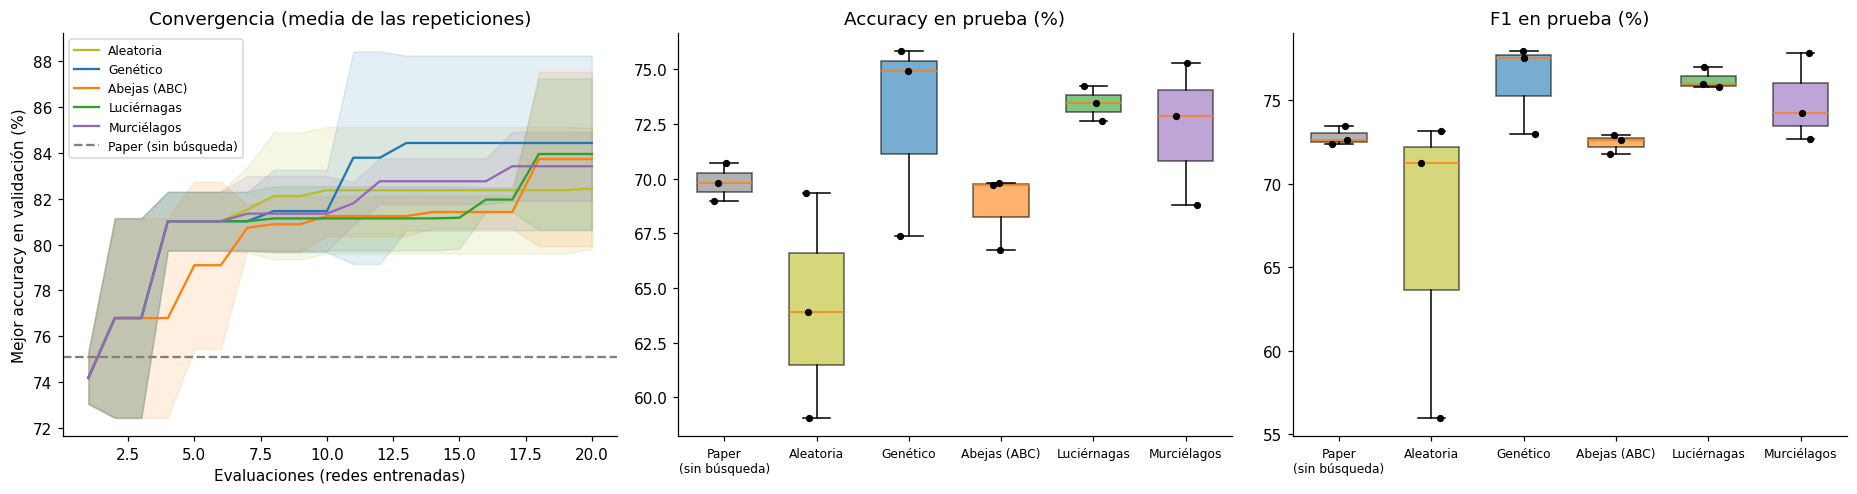

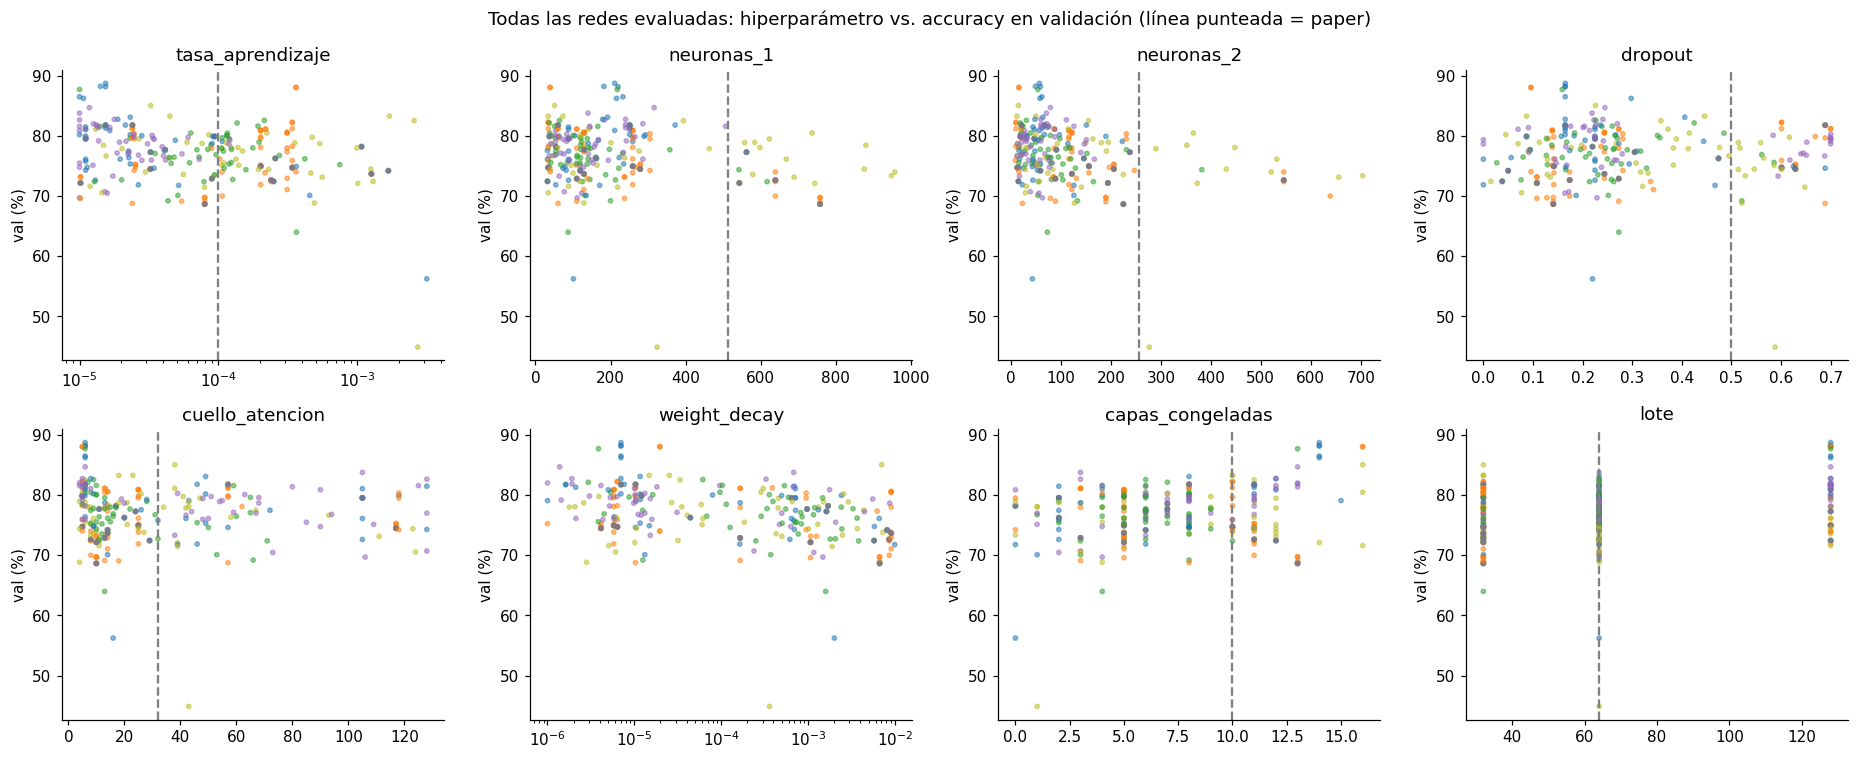

In [ ]:
colores = dict(zip(ORDEN, ["#7f7f7f", "#bcbd22", "#1f77b4", "#ff7f0e", "#2ca02c", "#9467bd"]))
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
for nombre in sm.ALGORITMOS:
    c = H1[H1.algoritmo == nombre].groupby("evaluacion")["mejor"].agg(["mean", "std"]).fillna(0)
    ax[0].plot(c.index, c["mean"] * 100, color=colores[nombre], label=nombre)
    ax[0].fill_between(c.index, (c["mean"] - c["std"]) * 100, (c["mean"] + c["std"]) * 100, color=colores[nombre], alpha=0.12)
ax[0].axhline(E1[E1.algoritmo == ORDEN[0]]["aptitud_val"].mean() * 100, color="gray", ls="--", label="Paper (sin búsqueda)")
ax[0].set(xlabel="Evaluaciones (redes entrenadas)", ylabel="Mejor accuracy en validación (%)", title="Convergencia (media de las repeticiones)"); ax[0].legend(fontsize=8)
for k, (col, tit) in enumerate([("accuracy_test", "Accuracy en prueba (%)"), ("f1_test", "F1 en prueba (%)")], 1):
    vals = [E1[E1.algoritmo == a][col] * 100 for a in ORDEN]
    b = ax[k].boxplot(vals, patch_artist=True, widths=0.6)
    for p, a in zip(b["boxes"], ORDEN): p.set_facecolor(colores[a]); p.set_alpha(0.6)
    for i, v in enumerate(vals, 1): ax[k].scatter(np.full(len(v), i) + np.random.uniform(-0.12, 0.12, len(v)), v, s=14, color="k", zorder=3)
    ax[k].set_xticks(range(1, len(ORDEN) + 1), [a.replace(" (sin búsqueda)", "\n(sin búsqueda)") for a in ORDEN], fontsize=8); ax[k].set_title(tit)
plt.tight_layout(); plt.savefig(CARPETA / "fig_experimento1.png", dpi=150); plt.show()

fig, ax = plt.subplots(2, 4, figsize=(17, 7))          # qué valores de cada hiperparámetro dan mejor aptitud
for a, n in zip(ax.ravel(), sr.CONFIG_PAPER):
    a.scatter(H1[n], H1["aptitud"] * 100, s=8, alpha=0.5, c=[colores[x] for x in H1.algoritmo])
    a.axvline(sr.CONFIG_PAPER[n], color="gray", ls="--"); a.set(title=n, ylabel="val (%)")
    if n in ("tasa_aprendizaje", "weight_decay"): a.set_xscale("log")
plt.suptitle("Todas las redes evaluadas: hiperparámetro vs. accuracy en validación (línea punteada = paper)"); plt.tight_layout()
plt.savefig(CARPETA / "fig_hiperparametros.png", dpi=150); plt.show()

### 2.3 Análisis estadístico: ANOVA de un factor

Modelo: $Y_{ij} = \mu + \tau_i + \varepsilon_{ij}$, donde $\tau_i$ es el efecto del método de búsqueda $i$.

- $H_0$: $\tau_1 = \dots = \tau_6 = 0$ (el método no cambia la accuracy).
- $H_a$: algún $\tau_i \neq 0$.

Si el valor *p* es menor que 0,05, se rechaza $H_0$ y la prueba de Tukey HSD indica qué pares de métodos difieren.

In [ ]:
import statsmodels.api as smx
from statsmodels.formula.api import ols
from statsmodels.stats.multicomp import pairwise_tukeyhsd
for resp in ["accuracy_test", "f1_test", "aptitud_val"]:
    tabla = smx.stats.anova_lm(ols(f"{resp} ~ C(algoritmo)", data=E1).fit(), typ=2)
    p = tabla.loc["C(algoritmo)", "PR(>F)"]
    print(f"\n=== ANOVA: {resp} ===  F = {tabla.loc['C(algoritmo)', 'F']:.2f}, p = {p:.4f} ->",
          "se RECHAZA H0: el método de búsqueda sí influye" if p < 0.05 else "no se rechaza H0: no hay diferencia significativa")
    display(tabla.round(5))
print(pairwise_tukeyhsd(E1["aptitud_val"], E1["algoritmo"], alpha=0.05))


=== ANOVA: accuracy_test ===  F = 3.45, p = 0.0367 -> se RECHAZA H0: el método de búsqueda sí influye


,sum_sq,df,F,PR(>F)
C(algoritmo),0.01815,5.0,3.44559,0.03672
Residual,0.01265,12.0,NaN,NaN



=== ANOVA: f1_test ===  F = 2.17, p = 0.1264 -> no se rechaza H0: no hay diferencia significativa


,sum_sq,df,F,PR(>F)
C(algoritmo),0.01887,5.0,2.16774,0.12636
Residual,0.02089,12.0,NaN,NaN



=== ANOVA: aptitud_val ===  F = 4.39, p = 0.0166 -> se RECHAZA H0: el método de búsqueda sí influye


,sum_sq,df,F,PR(>F)
C(algoritmo),0.01869,5.0,4.39224,0.01663
Residual,0.01021,12.0,NaN,NaN


          Multiple Comparison of Means - Tukey HSD, FWER=0.05           
   group1           group2        meandiff p-adj   lower   upper  reject
------------------------------------------------------------------------
Abejas (ABC)            Aleatoria  -0.0128 0.9933 -0.0928  0.0672  False
Abejas (ABC)             Genético    0.007 0.9996  -0.073   0.087  False
Abejas (ABC)          Luciérnagas   0.0022    1.0 -0.0778  0.0822  False
Abejas (ABC)          Murciélagos  -0.0031    1.0 -0.0831  0.0769  False
Abejas (ABC) Paper (sin búsqueda)  -0.0863 0.0321 -0.1663 -0.0063   True
   Aleatoria             Genético   0.0198 0.9554 -0.0602  0.0998  False
   Aleatoria          Luciérnagas    0.015 0.9862  -0.065   0.095  False
   Aleatoria          Murciélagos   0.0097 0.9982 -0.0703  0.0897  False
   Aleatoria Paper (sin búsqueda)  -0.0734  0.079 -0.1534  0.0066  False
    Genético          Luciérnagas  -0.0048 0.9999 -0.0848  0.0752  False
    Genético          Murciélagos  -0.0101 0.9977 -

## 3. Experimento 2: reglas evolutivas (Michigan vs. Pittsburgh)

En la red original, la decisión final (alerta o somnoliento) la toma una **regresión logística** sobre $[z_L, z_R, \text{cierre}_L, \text{cierre}_R]$. Aquí se reemplaza por reglas `SI … ENTONCES …` aprendidas con algoritmos genéticos:

- **Michigan** (estilo UCS): cada individuo es **una regla**. Toda la población forma el clasificador, las reglas compiten por su precisión y el AG actúa dentro del conjunto de reglas que aciertan.
- **Pittsburgh** (estilo GABIL): cada individuo es **un conjunto completo de reglas** (lista de decisión con clase por defecto), y el AG evoluciona clasificadores enteros.

Se usan los cierres que ya predijeron las redes del experimento 1 (guardados en la caché), así que este experimento no vuelve a entrenar la VGG19.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
mejor_alg = E1[E1.algoritmo != ORDEN[0]].groupby("algoritmo")["aptitud_val"].mean().idxmax()   # elegido por VALIDACIÓN
print("Red optimizada = la mejor configuración de", mejor_alg, "en cada repetición")

def caracteristicas(clave):
    z = np.load(CACHE / f"{clave}.npz")
    out = {}
    for p in ("train", "test"):
        Fp, ok = sm.calibrar(D.cal, D.idx[p], z[p]); out[p] = (Fp[ok], D.cal.label[D.idx[p]][ok])
    return out

filas2, REGLAS = [], {}
for rep in range(REPETICIONES):
    for red, clave in [("Original (paper)", E1[(E1.algoritmo == ORDEN[0]) & (E1.repeticion == rep)]["clave"].iloc[0]),
                       (f"Optimizada ({mejor_alg})", E1[(E1.algoritmo == mejor_alg) & (E1.repeticion == rep)]["clave"].iloc[0])]:
        X = caracteristicas(clave); (Xtr, ytr), (Xte, yte) = X["train"], X["test"]
        clfs = {"Regresión logística": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")),
                "Michigan": sm.Michigan(rng=np.random.default_rng(rep)), "Pittsburgh": sm.Pittsburgh(rng=np.random.default_rng(rep))}
        for nombre, clf in clfs.items():
            t0 = time.time(); clf.fit(Xtr, ytr); p = clf.predict(Xte)
            n_reglas = len(clf.mejor_[2]) + 1 if nombre == "Pittsburgh" else int((clf.exp > 5).sum()) if nombre == "Michigan" else np.nan
            filas2.append({"clasificador": nombre, "red": red, "repeticion": rep, **sm.metricas(yte, p), "n_reglas": n_reglas, "segundos": time.time() - t0})
            if rep == 0 and nombre != "Regresión logística": REGLAS[(nombre, red)] = clf.reglas()
E2 = pd.DataFrame(filas2); E2.to_csv(CARPETA / "experimento2.csv", index=False)
g2 = E2.groupby(["clasificador", "red"])
T2 = pd.DataFrame({m + " (%)": (g2[m].mean() * 100).round(1).astype(str) + " ± " + (g2[m].std() * 100).round(1).astype(str)
                   for m in ["accuracy", "f1", "recall_drowsy", "recall_alerta"]}).assign(Reglas=g2["n_reglas"].mean().round(1))
T2.to_csv(CARPETA / "tabla_experimento2.csv"); T2

Red optimizada = la mejor configuración de Genético en cada repetición


accuracy (%)      f1 (%)  \
clasificador        red                                              
Michigan            Optimizada (Genético)   64.4 ± 9.7  72.3 ± 5.6   
                    Original (paper)        69.6 ± 9.8  72.8 ± 6.2   
Pittsburgh          Optimizada (Genético)   70.9 ± 2.0  75.3 ± 2.1   
                    Original (paper)        70.3 ± 0.7  73.7 ± 0.3   
Regresión logística Optimizada (Genético)   72.7 ± 4.6  76.2 ± 2.7   
                    Original (paper)        69.8 ± 0.9  72.8 ± 0.6   

                                          recall_drowsy (%) recall_alerta (%)  \
clasificador        red                                                         
Michigan            Optimizada (Genético)        91.4 ± 4.3       37.4 ± 20.8   
                    Original (paper)             79.7 ± 1.6       59.4 ± 19.8   
Pittsburgh          Optimizada (Genético)        89.1 ± 4.2        52.6 ± 1.6   
                    Original (paper)             83.0 ± 1.0        57.6 ± 2.3   
Regresión logística Optimizada (Genético)        86.7 ± 1.5       58.7 ± 10.7   
                    Original (paper)             80.8 ± 0.7        58.9 ± 2.0   

                                           Reglas  
clasificador        red                            
Michigan            Optimizada (Genético)   119.0  
                    Original (paper)        120.0  
Pittsburgh          Optimizada (Genético)     2.7  
                    Original (paper)          2.7  
Regresión logística Optimizada (Genético)     NaN  
                    Original (paper)          NaN

In [ ]:
for (nombre, red), reglas in REGLAS.items():
    print(f"\n--- {nombre} | red {red} ---")
    for r in reglas[:8]:
        print("  ", r if isinstance(r, str) else f"{r[0]}   (precisión {r[1]:.2f}, usada {r[2]} veces)")


--- Michigan | red Original (paper) ---
   SI z_L ∈ [2.06, 5.04] Y z_R ∈ [5.47, 8.25] Y closure_L ∈ [0.13, 0.26] → Drowsy   (precisión 0.98, usada 182 veces)
   SI z_L ∈ [2.06, 5.04] Y z_R ∈ [5.47, 8.25] Y closure_L ∈ [0.13, 0.26] → Drowsy   (precisión 0.98, usada 181 veces)
   SI z_L ∈ [2.06, 5.04] Y z_R ∈ [5.47, 8.25] Y closure_L ∈ [0.13, 0.26] → Drowsy   (precisión 0.98, usada 180 veces)
   SI z_L ∈ [2.06, 5.04] Y z_R ∈ [5.47, 8.25] Y closure_L ∈ [0.13, 0.26] → Drowsy   (precisión 0.98, usada 179 veces)
   SI z_R ∈ [3.62, 7.05] → Drowsy   (precisión 0.95, usada 1198 veces)
   SI z_R ∈ [3.62, 7.05] → Drowsy   (precisión 0.95, usada 1179 veces)
   SI z_R ∈ [3.62, 7.05] → Drowsy   (precisión 0.95, usada 1171 veces)
   SI z_R ∈ [3.62, 7.05] Y closure_L ∈ [-0.14, 0.40] Y closure_R ∈ [-0.13, 0.45] → Drowsy   (precisión 0.94, usada 717 veces)

--- Pittsburgh | red Original (paper) ---
   SI z_L ∈ [-2.27, 1.46] Y z_R ∈ [-1.63, 2.16] Y closure_R ∈ [-0.12, 0.20] → Alerta
   SI z_L ∈ [-2.40, 

In [ ]:
from google.colab import drive; drive.mount("/content/drive")
!python /content/drive/MyDrive/SomnIA_colab/guardar_pesos.py

Mounted at /content/drive
Downloading: "https://download.pytorch.org/models/vgg19-dcbb9e9d.pth" to /root/.cache/torch/hub/checkpoints/vgg19-dcbb9e9d.pth
100% 548M/548M [00:02<00:00, 216MB/s]
Abejas (ABC): vgg19_attention_ojos_abejas.pt (0.1 MB) | F1 test original 0.726 / guardado 0.726
Aleatoria: vgg19_attention_ojos_aleatoria.pt (0.1 MB) | F1 test original 0.560 / guardado 0.560
Genético: vgg19_attention_ojos_genetico.pt (9.3 MB) | F1 test original 0.730 / guardado 0.730
Luciérnagas: vgg19_attention_ojos_luciernagas.pt (13.8 MB) | F1 test original 0.760 / guardado 0.760
Murciélagos: vgg19_attention_ojos_murcielagos.pt (13.9 MB) | F1 test original 0.778 / guardado 0.778
Paper (sin búsqueda): vgg19_attention_ojos_paper.pt (27.8 MB) | F1 test original 0.726 / guardado 0.726
FIN


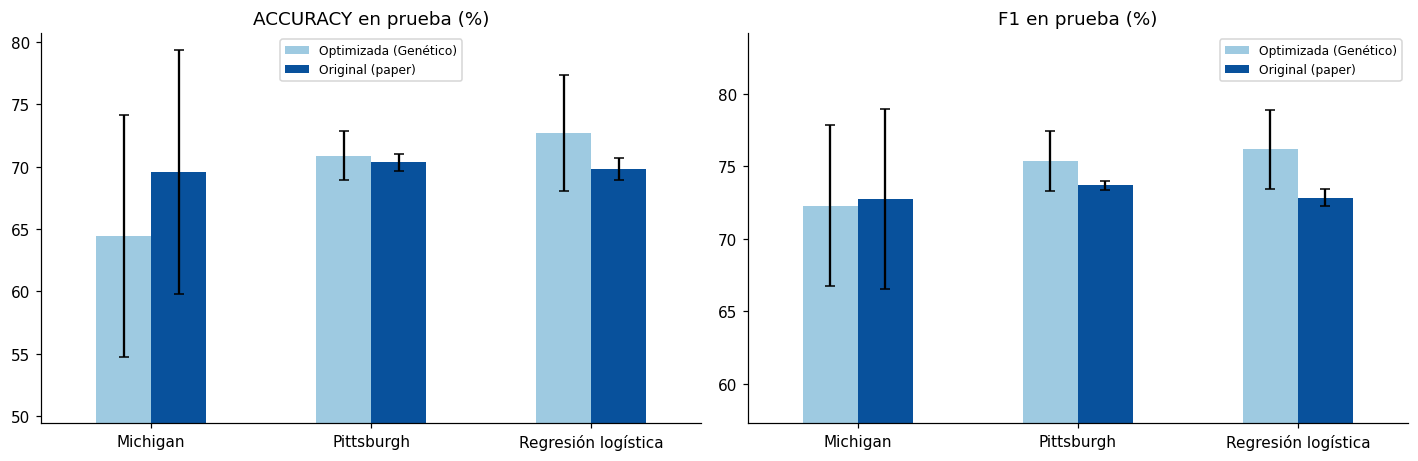

ANOVA de dos factores con interacción (accuracy en prueba):


,sum_sq,df,F,PR(>F)
C(clasificador),0.00638,2.0,0.88365,0.43853
C(red),0.00016,1.0,0.04309,0.83903
C(clasificador):C(red),0.00509,2.0,0.70539,0.51329
Residual,0.04331,12.0,NaN,NaN


  clasificador   : p = 0.4385 -> no significativo
  red de entrada : p = 0.8390 -> no significativo
  interacción    : p = 0.5133 -> no significativo


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
for k, m in enumerate(["accuracy", "f1"]):
    piv = E2.groupby(["clasificador", "red"])[m].mean().unstack() * 100; err = E2.groupby(["clasificador", "red"])[m].std().unstack() * 100
    piv.plot.bar(yerr=err, ax=ax[k], rot=0, capsize=3, color=["#9ecae1", "#08519c"])
    ax[k].set(title=f"{m.upper()} en prueba (%)", xlabel="", ylim=(max(0, piv.values.min() - 15), min(100, piv.values.max() + 8))); ax[k].legend(fontsize=8)
plt.tight_layout(); plt.savefig(CARPETA / "fig_experimento2.png", dpi=150); plt.show()
A2 = smx.stats.anova_lm(ols("accuracy ~ C(clasificador) * C(red)", data=E2).fit(), typ=2)
print("ANOVA de dos factores con interacción (accuracy en prueba):"); display(A2.round(5))
for f, nombre in [("C(clasificador)", "clasificador"), ("C(red)", "red de entrada"), ("C(clasificador):C(red)", "interacción")]:
    print(f"  {nombre:15s}: p = {A2.loc[f, 'PR(>F)']:.4f} ->", "influye (p < 0,05)" if A2.loc[f, "PR(>F)"] < 0.05 else "no significativo")

## 4. Conclusiones

In [ ]:
m1 = E1.groupby("algoritmo")["accuracy_test"].mean().reindex(ORDEN)
log(f"Experimento 1: el paper logra {m1.iloc[0]:.1%} de accuracy en prueba; la mejor metaheurística en validación es {mejor_alg} "
    f"({m1[mejor_alg]:.1%} en prueba, {(m1[mejor_alg] - m1.iloc[0]) * 100:+.1f} puntos).")
m2 = E2.groupby("clasificador")["accuracy"].mean()
log(f"Experimento 2: regresión logística {m2['Regresión logística']:.1%} | Michigan {m2['Michigan']:.1%} | Pittsburgh {m2['Pittsburgh']:.1%}.")
print("Resultados, tablas y figuras guardados en Drive:", CARPETA)

Experimento 1: el paper logra 69.8% de accuracy en prueba; la mejor metaheurística en validación es Genético (72.7% en prueba, +2.9 puntos).
Experimento 2: regresión logística 71.3% | Michigan 67.0% | Pittsburgh 70.6%.
Resultados, tablas y figuras guardados en Drive: /content/drive/MyDrive/SomnIA_colab
